# EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/heart_augmented_4500.csv")

In [21]:
df.head()
# df.tail()
# df.shape
# df.columns

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             4500 non-null   int64  
 1   Sex             4500 non-null   str    
 2   ChestPainType   4500 non-null   str    
 3   RestingBP       4500 non-null   int64  
 4   Cholesterol     4500 non-null   int64  
 5   FastingBS       4500 non-null   int64  
 6   RestingECG      4500 non-null   str    
 7   MaxHR           4500 non-null   int64  
 8   ExerciseAngina  4500 non-null   str    
 9   Oldpeak         4500 non-null   float64
 10  ST_Slope        4500 non-null   str    
 11  HeartDisease    4500 non-null   int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 422.0 KB


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000
mean,53.505778,132.339778,198.880000,0.230000,136.919778,0.855007,0.547333
std,9.429266,18.303652,109.817312,0.420879,25.761451,1.055330,0.497810
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,171.000000,0.000000,119.000000,0.000000,0.000000
50%,54.000000,131.000000,221.000000,0.000000,138.000000,0.470000,1.000000
75%,60.000000,142.000000,266.000000,0.000000,157.000000,1.522500,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [5]:
df.isnull().sum()
# df.duplicated().sum()
# df.nunique()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [6]:
refined_df = df.drop_duplicates()
# refined_df.shape
refined_df.to_csv("../data/processed/heart_cleaned.csv", index=False)

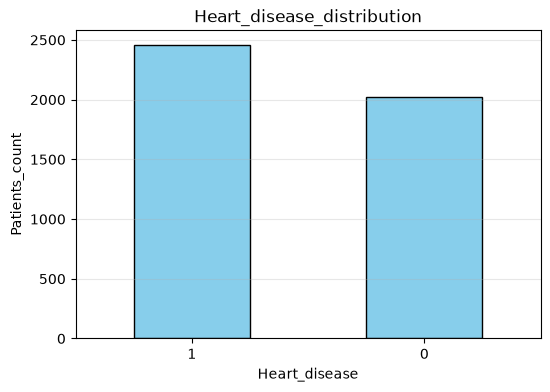

In [7]:
refined_df["HeartDisease"].value_counts().plot(kind="bar", figsize=(6,4), color="skyblue",
    edgecolor="black")
plt.xlabel("Heart_disease")
plt.ylabel("Patients_count")
plt.title("Heart_disease_distribution")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [8]:
refined_df.select_dtypes(include="number")
refined_df.select_dtypes(include="object")

C:\Users\Arkapravo Roy\AppData\Local\Temp\ipykernel_4108\68380945.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  refined_df.select_dtypes(include="object")


,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
0,M,ATA,Normal,N,Up
1,F,NAP,Normal,N,Flat
2,M,ATA,ST,N,Up
3,F,ASY,Normal,Y,Flat
4,M,NAP,Normal,N,Up
...,...,...,...,...,...
4495,M,ASY,Normal,N,Up
4496,M,ASY,ST,N,Up
4497,F,ASY,LVH,N,Up
4498,M,ATA,Normal,N,Up


In [9]:
categorical_columns = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
numerical_columns = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

## Bar graphs for numerical & categorical columns

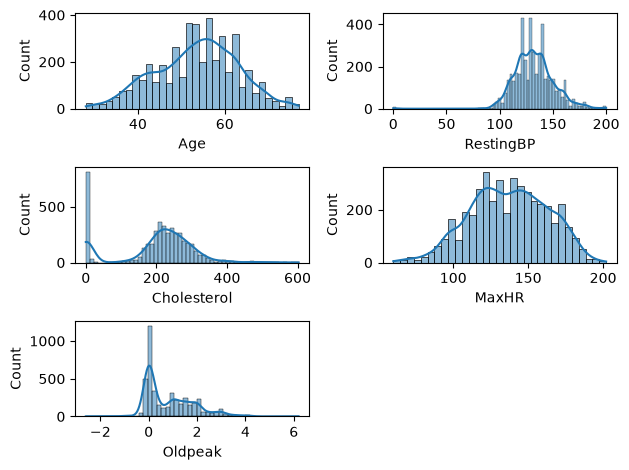

In [10]:
def plotting(var, num):
    plt.subplot(3,2, num)
    sns.histplot(refined_df[var], kde=True)
    
for i, var in enumerate(numerical_columns, 1):
    plotting(var, i)
plt.tight_layout()
plt.show()

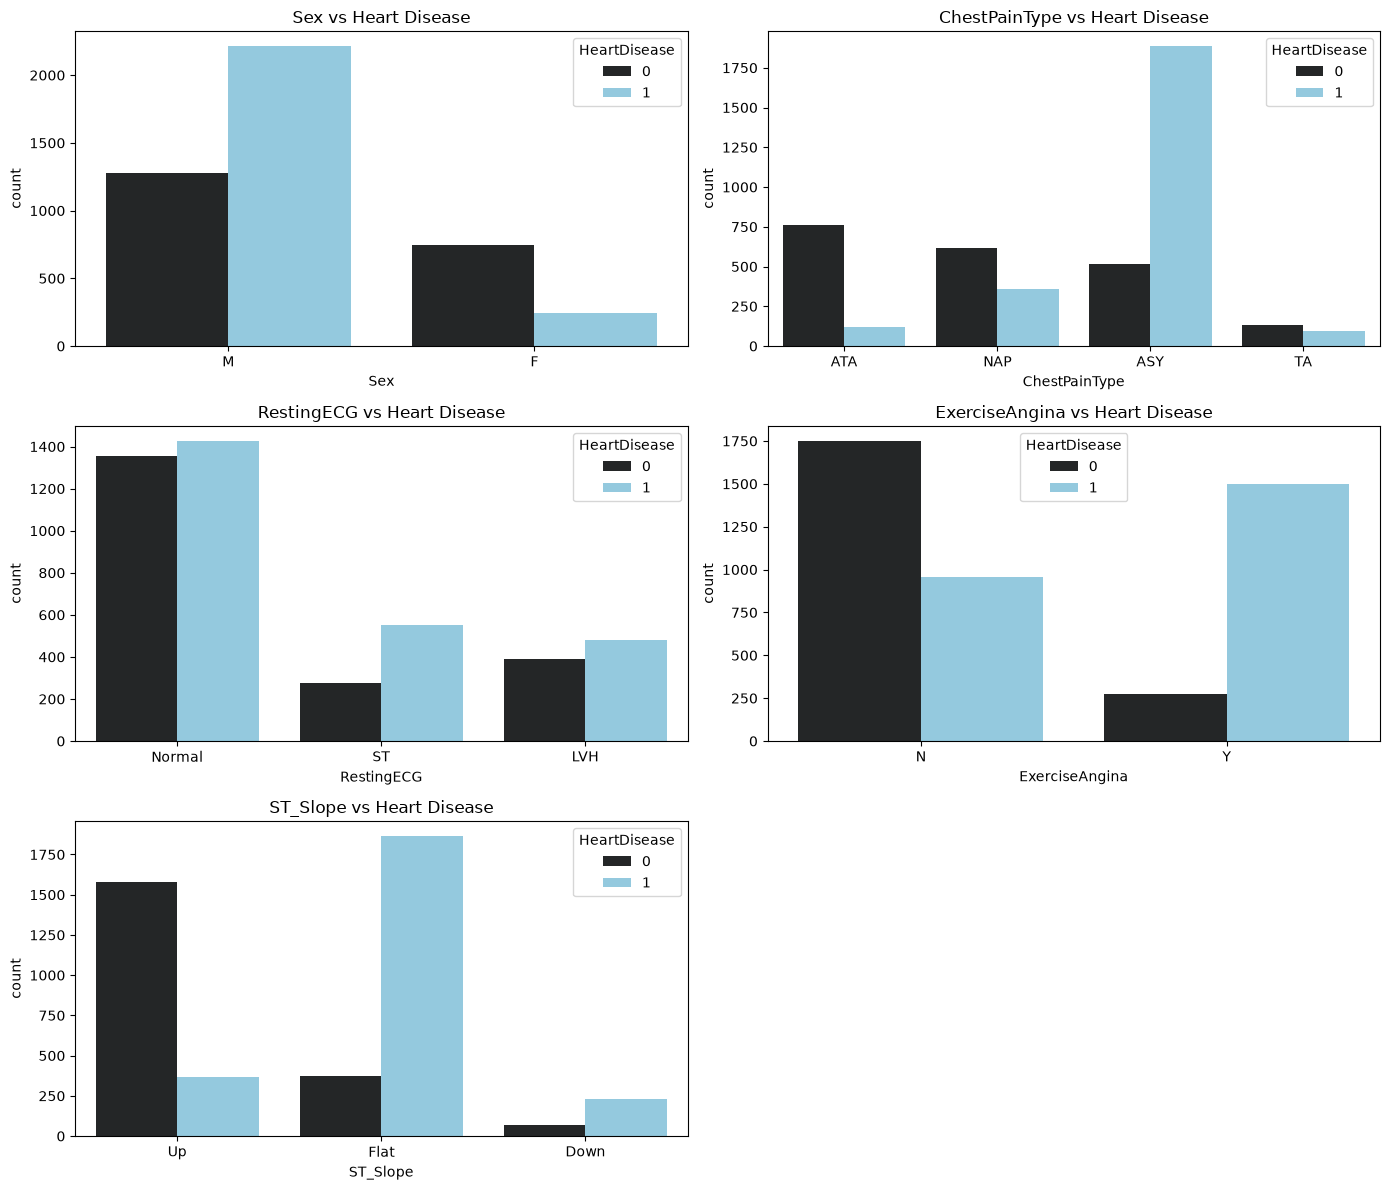

In [11]:
def plotting2(var, num):
    plt.subplot(3, 2, num)
    sns.countplot(
        x=refined_df[var],
        hue=refined_df["HeartDisease"],
        palette="dark:skyblue"
    )
    plt.title(f"{var} vs Heart Disease")
plt.figure(figsize=(14, 12))

for num, var in enumerate(categorical_columns, 1):
    plotting2(var, num)

plt.tight_layout()
plt.show()

In [12]:
# calculate the percentage 
for num in categorical_columns:
    heart_yes = refined_df.groupby(num)["HeartDisease"].mean() * 100
    print("-------------------")
    print(f"{num} vs Heart Disease:\n{heart_yes}")
    print("-------------------")
    

-------------------
Sex vs Heart Disease:
Sex
F    24.520686
M    63.464296
Name: HeartDisease, dtype: float64
-------------------
-------------------
ChestPainType vs Heart Disease:
ChestPainType
ASY    78.607173
ATA    13.553531
NAP    36.680328
TA     41.592920
Name: HeartDisease, dtype: float64
-------------------
-------------------
RestingECG vs Heart Disease:
RestingECG
LVH       55.057471
Normal    51.295896
ST        66.506024
Name: HeartDisease, dtype: float64
-------------------
-------------------
ExerciseAngina vs Heart Disease:
ExerciseAngina
N    35.331114
Y    84.563380
Name: HeartDisease, dtype: float64
-------------------
-------------------
ST_Slope vs Heart Disease:
ST_Slope
Down    77.551020
Flat    83.206789
Up      18.766067
Name: HeartDisease, dtype: float64
-------------------


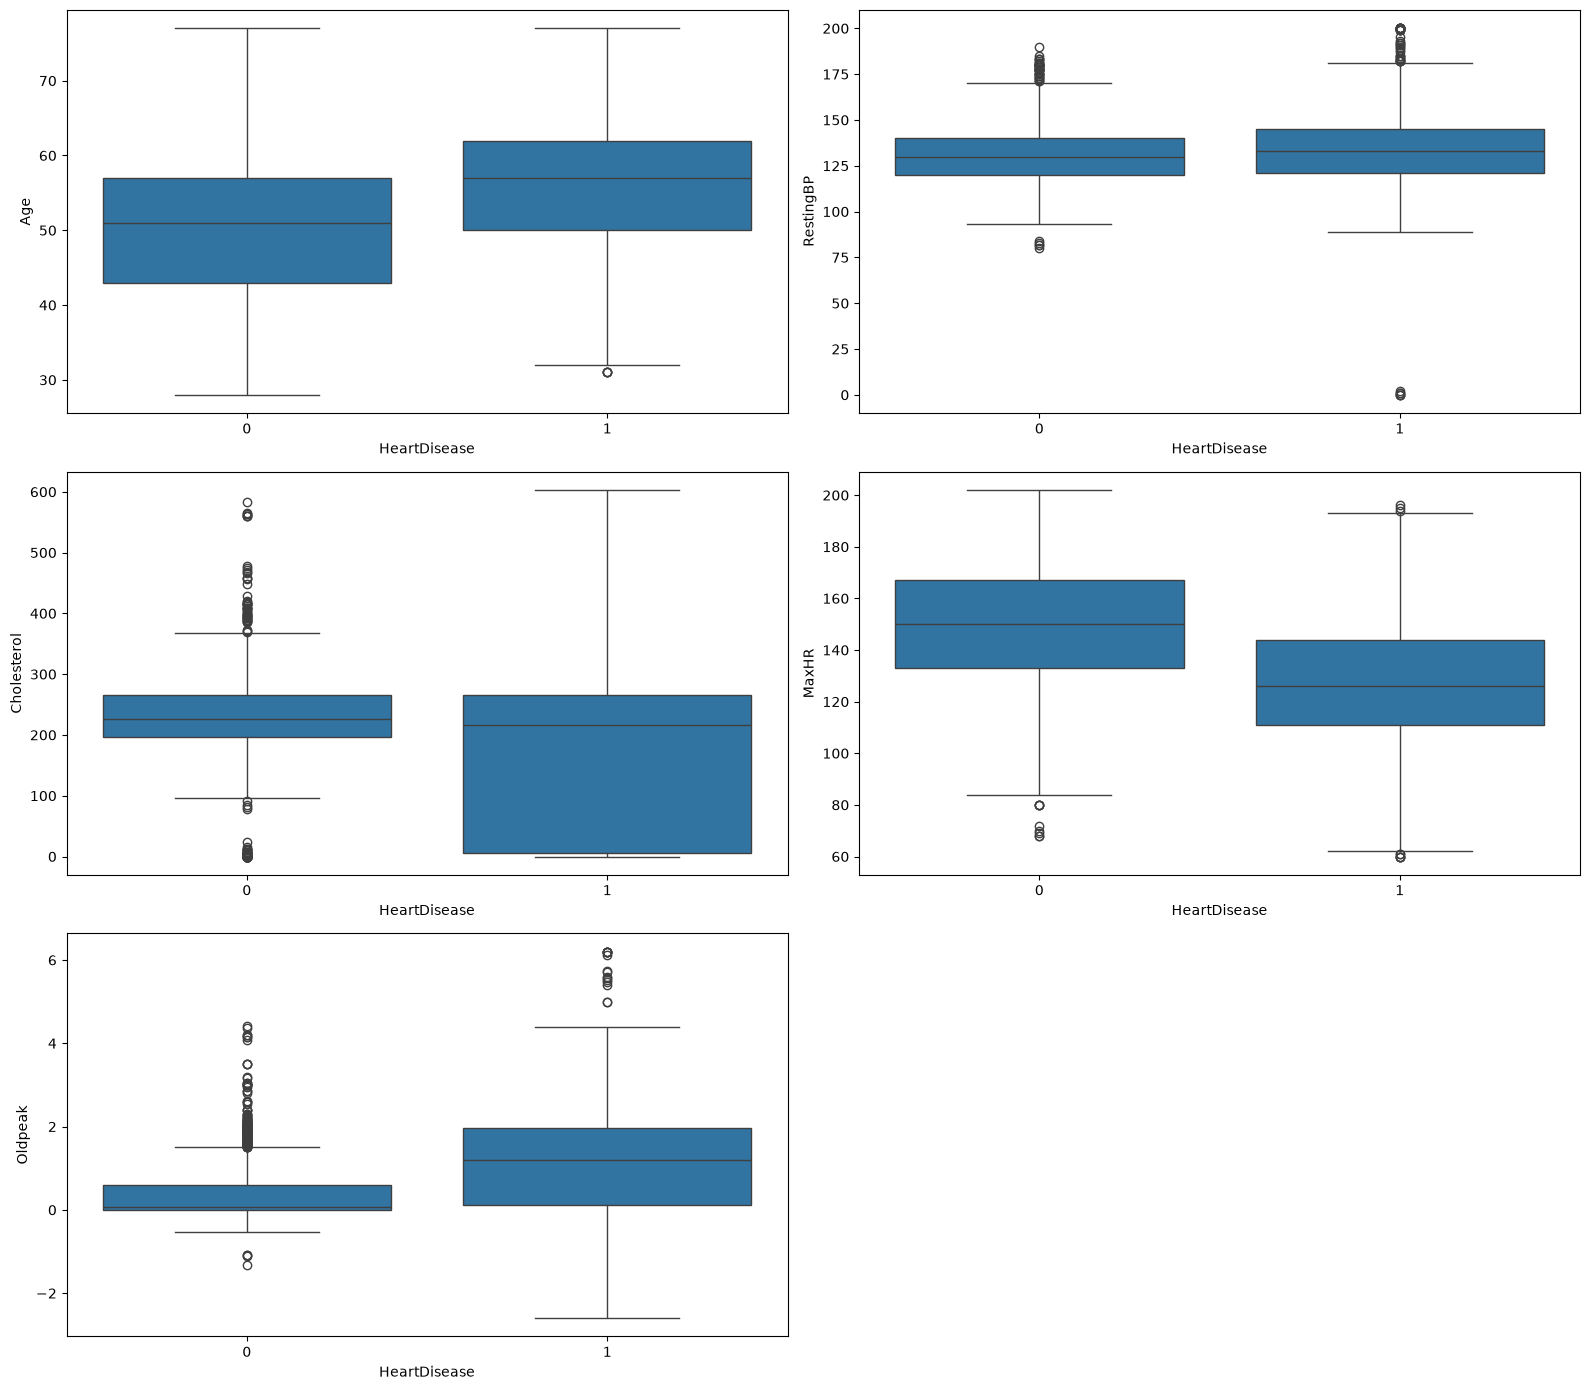

In [13]:
# Boxplots
def plotting3(var, num):
    plt.subplot(3,2, num)
    sns.boxplot(y=var, x="HeartDisease", data=refined_df)
plt.figure(figsize=(16,14))

for num,var in enumerate(numerical_columns, 1):
    plotting3(var, num)

plt.tight_layout()
plt.show()

<Axes: >

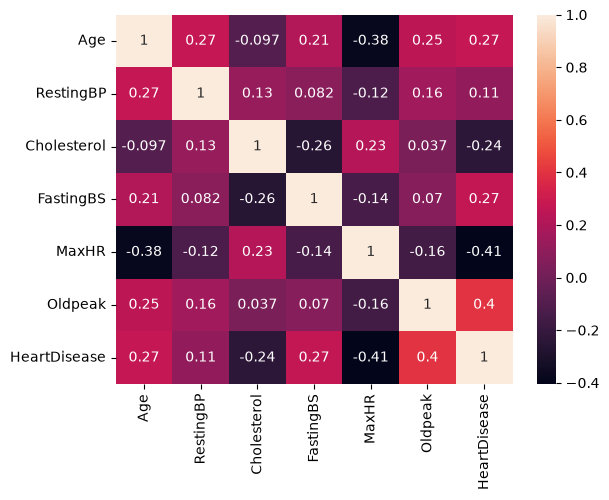

In [14]:
sns.heatmap(refined_df.corr(numeric_only=True), annot=True)

<Axes: xlabel='RestingBP', ylabel='MaxHR'>

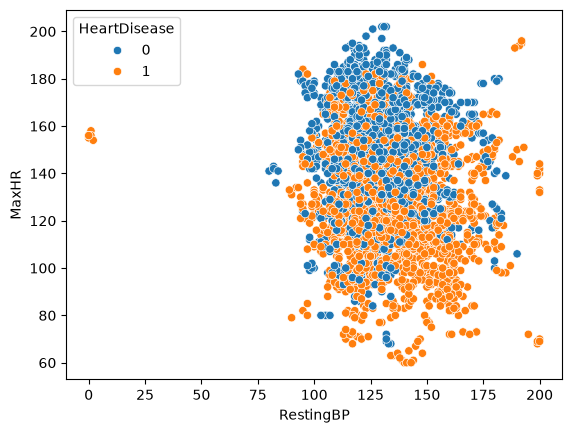

In [15]:
sns.scatterplot(data=refined_df, x="RestingBP", y="MaxHR", hue="HeartDisease")

# Outliers detection and cleaning

In [16]:
bp_mean = refined_df.loc[refined_df["RestingBP"] != 0, "RestingBP"].mean()
refined_df["RestingBP"] = refined_df["RestingBP"].replace(0, bp_mean)

In [17]:
ch_mean = refined_df.loc[refined_df["Cholesterol"] != 0, "Cholesterol"].mean()
refined_df["Cholesterol"] = refined_df["Cholesterol"].replace(0, ch_mean)
# plotting("Cholesterol", 1)

Now if we check every graphs they will look good

for numeric bar plots

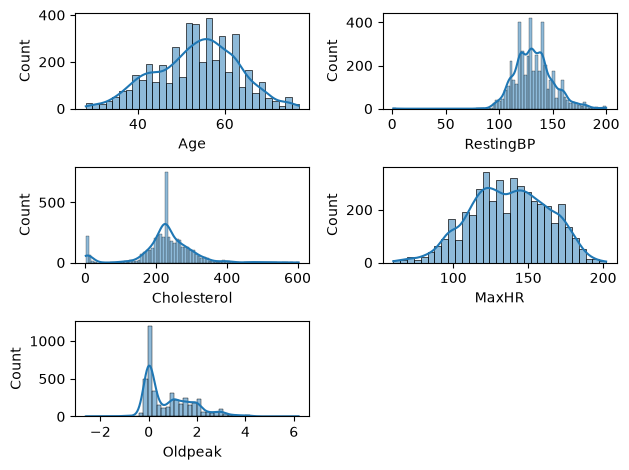

In [18]:
for i, var in enumerate(numerical_columns, 1):
    plotting(var, i)
plt.tight_layout()
plt.show()

for countplots

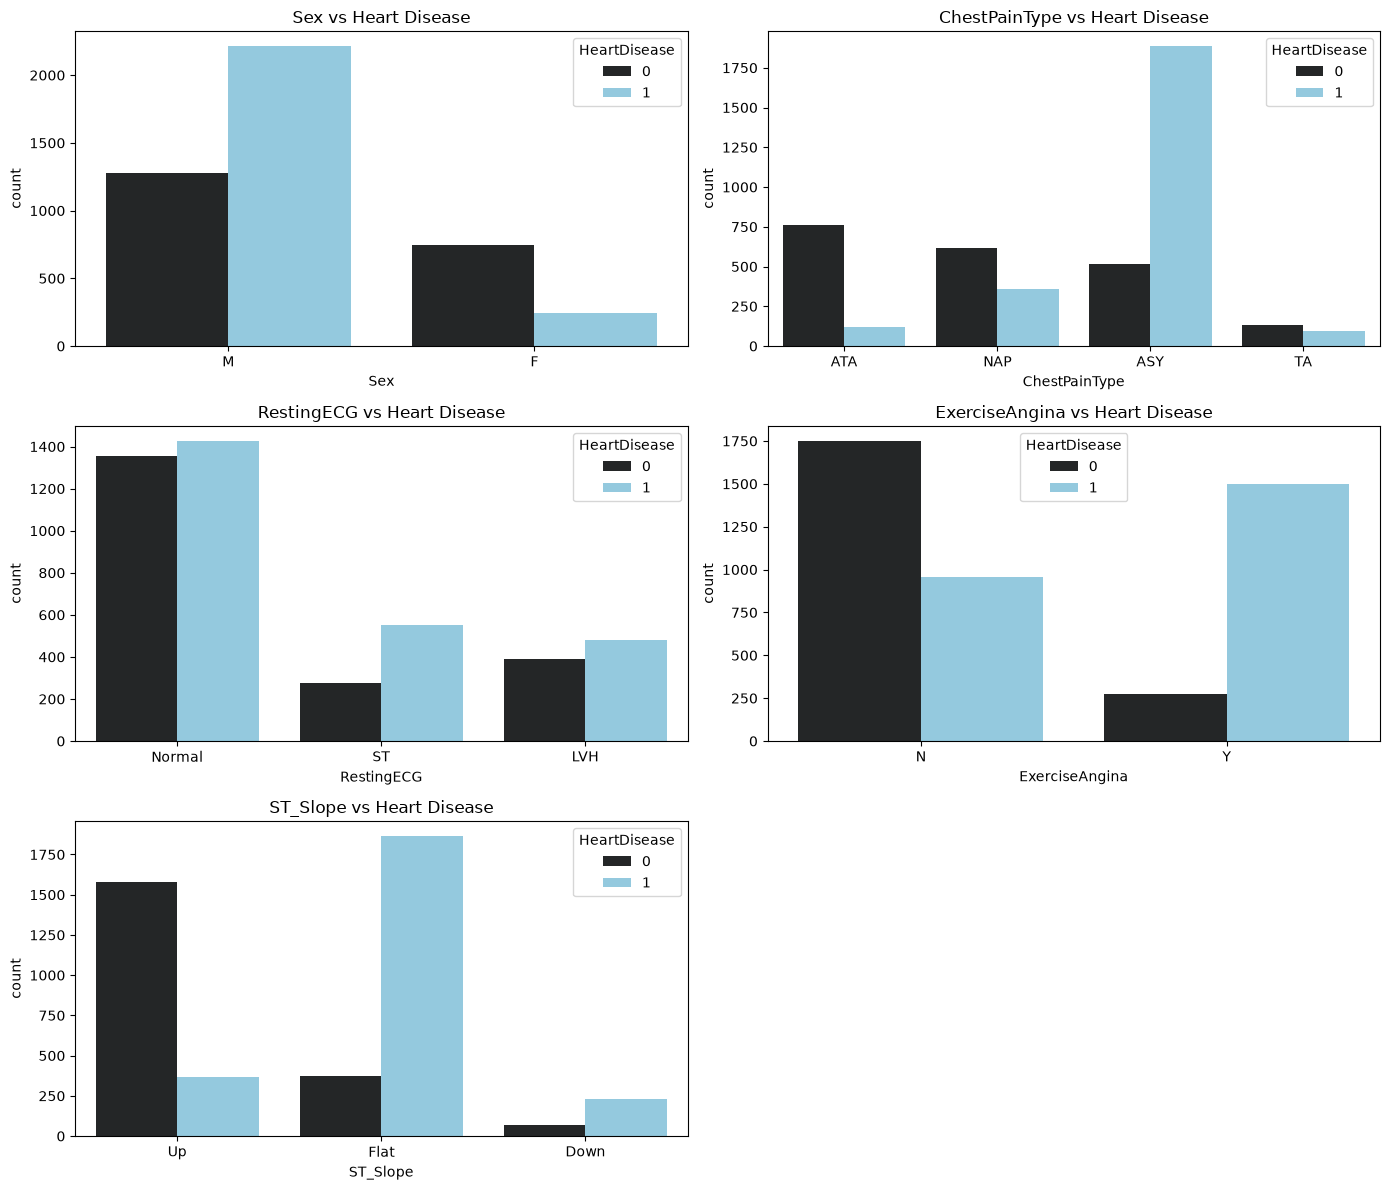

In [19]:
def plotting2(var, num):
    plt.subplot(3, 2, num)
    sns.countplot(
        x=refined_df[var],
        hue=refined_df["HeartDisease"],
        palette="dark:skyblue"
    )
    plt.title(f"{var} vs Heart Disease")
plt.figure(figsize=(14, 12))

for num, var in enumerate(categorical_columns, 1):
    plotting2(var, num)

plt.tight_layout()
plt.show()